# import linraries

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import sys
sys.path.append("..")

from src.config import cfg

## import data

In [2]:
from src.data_loader import load_raw
df = load_raw()
df.head()

2026-11-23 15:56:52,629 | INFO | src.data_loader | data loaded


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


## Convert `Datetime` to datetime type

In [3]:
print("Type before:", df[cfg.DATETIME_COL].dtype)
df[cfg.DATETIME_COL] = pd.to_datetime(df[cfg.DATETIME_COL], errors="coerce")
print("Type after: ", df[cfg.DATETIME_COL].dtype)
print("Unparsed dates (NaT):", df[cfg.DATETIME_COL].isna().sum())


Type before: str
Type after:  datetime64[us]
Unparsed dates (NaT): 0


## Structure, types and shape

In [4]:
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
df.info()

Shape: (145366, 2)

Datetime    datetime64[us]
PJME_MW            float64
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[us]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.2 MB


## Descriptive statistics

In [4]:
df[[cfg.TARGET_COL]].describe().T

,count,mean,std,min,25%,50%,75%,max
PJME_MW,145366.0,32080.222831,6464.012166,14544.0,27573.0,31421.0,35650.0,62009.0


In [5]:
print(df[cfg.TARGET_COL].quantile([0, 0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1]))
print("\nValues <= 0:", (df[cfg.TARGET_COL] <= 0).sum())
print("Skewness:", round(df[cfg.TARGET_COL].skew(), 3))

0.000    14544.000
0.001    19917.555
0.010    20969.300
0.050    22623.000
0.250    27573.000
0.500    31421.000
0.750    35650.000
0.950    44187.750
0.990    51156.400
0.999    56712.985
1.000    62009.000
Name: PJME_MW, dtype: float64

Values <= 0: 0
Skewness: 0.739


/tmp/ipykernel_243355/3597230321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(df[cfg.TARGET_COL], vert=False)


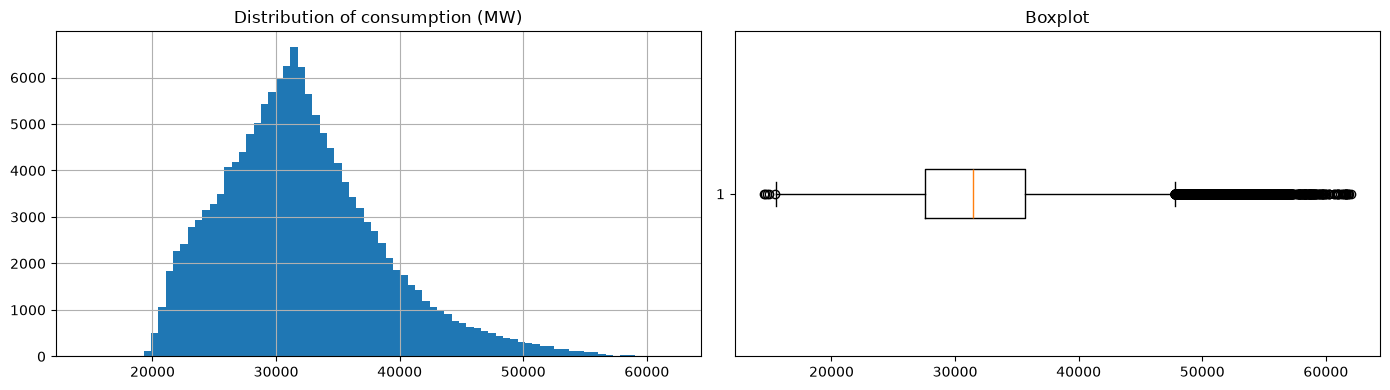

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[cfg.TARGET_COL].hist(bins=80, ax=ax[0])
ax[0].set_title("Distribution of consumption (MW)")
ax[1].boxplot(df[cfg.TARGET_COL], vert=False)
ax[1].set_title("Boxplot")
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "01_distribution.png")
plt.show()

## Missing values

In [7]:
missing = df.isna().sum().to_frame('missing')
missing['pst'] = (missing['missing'] / len(df) * 100).round(2)
missing

,missing,pst
Datetime,0,0.0
PJME_MW,0,0.0


## Duplicates and chronological order

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df[cfg.DATETIME_COL].duplicated().sum())
print("Sorted chronologically:", df[cfg.DATETIME_COL].is_monotonic_increasing)

out_of_order = df[cfg.DATETIME_COL].diff() < pd.Timedelta(0)
print("Out-of-order rows:", out_of_order.sum())
df[out_of_order].head()

Duplicate rows: 0
Duplicate timestamps: 4
Sorted chronologically: False
Out-of-order rows: 6041


,Datetime,PJME_MW
24,2002-12-30 01:00:00,27526.0
48,2002-12-29 01:00:00,27084.0
72,2002-12-28 01:00:00,29344.0
96,2002-12-27 01:00:00,28445.0
120,2002-12-26 01:00:00,26705.0


In [9]:
# Duplicated timestamps: same hour, different values
df[df[cfg.DATETIME_COL].duplicated(keep=False)].sort_values(cfg.DATETIME_COL)

,Datetime,PJME_MW
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
115368,2015-11-01 02:00:00,21567.0
115369,2015-11-01 02:00:00,21171.0
124008,2016-11-06 02:00:00,20795.0
124009,2016-11-06 02:00:00,21692.0
132816,2017-11-05 02:00:00,21236.0
132817,2017-11-05 02:00:00,20666.0


## Temporal distribution: period, frequency and gaps
Work on a sorted, de-duplicated copy of the timestamps (the raw `df` stays untouched).

In [10]:
d = df[cfg.DATETIME_COL].dropna().sort_values().drop_duplicates().reset_index(drop=True)

print("Start:", d.min())
print("End:  ", d.max())
print("Span: ", d.max() - d.min())

deltas = d.diff().dropna()
print("\nTime step between consecutive observations:")
print(deltas.value_counts())

expected = deltas.mode()[0]
print("\nExpected frequency:", expected)

Start: 2002-01-01 01:00:00
End:   2018-08-03 00:00:00
Span:  6057 days 23:00:00

Time step between consecutive observations:
Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
Name: count, dtype: int64

Expected frequency: 0 days 01:00:00


In [15]:
gaps = deltas[deltas > expected]

values = (
    df.groupby(cfg.DATETIME_COL)[cfg.TARGET_COL]
    .mean()
)
gap_table = pd.DataFrame({
    "gap_after": d.shift(1)[gaps.index],
    "next_obs": d[gaps.index],
    "duration": gaps,
    "value_before_gap": values.reindex(d.shift(1)[gaps.index]).values,
    "value_after_gap": values.reindex(d[gaps.index]).values
}).reset_index(drop=True)

print("Number of gaps:", len(gap_table))
gap_table

Number of gaps: 30


,gap_after,next_obs,duration,value_before_gap,value_after_gap
0,2002-04-07 02:00:00,2002-04-07 04:00:00,0 days 02:00:00,24738.0,24487.0
1,2002-10-27 01:00:00,2002-10-27 03:00:00,0 days 02:00:00,22823.0,20605.0
2,2003-04-06 02:00:00,2003-04-06 04:00:00,0 days 02:00:00,23345.0,22902.0
3,2003-10-26 01:00:00,2003-10-26 03:00:00,0 days 02:00:00,23003.0,20641.0
4,2004-04-04 02:00:00,2004-04-04 04:00:00,0 days 02:00:00,23501.0,23208.0
5,2004-10-31 01:00:00,2004-10-31 03:00:00,0 days 02:00:00,23027.0,20585.0
6,2005-04-03 02:00:00,2005-04-03 04:00:00,0 days 02:00:00,23740.0,23414.0
7,2005-10-30 01:00:00,2005-10-30 03:00:00,0 days 02:00:00,25623.0,23302.0
8,2006-04-02 02:00:00,2006-04-02 04:00:00,0 days 02:00:00,21456.0,20833.0
9,2006-10-29 01:00:00,2006-10-29 03:00:00,0 days 02:00:00,25374.0,23310.0


In [16]:
expected_count = int((d.max() - d.min()) / expected) + 1
print(f"Distinct observations: {len(d)}")
print(f"Expected observations: {expected_count}")
print(f"Missing hours:         {expected_count - len(d)}")
print(f"Completeness:          {len(d) / expected_count:.3%}")

Distinct observations: 145362
Expected observations: 145392
Missing hours:         30
Completeness:          99.979%


### Are gaps / duplicates linked to daylight saving time (DST)?

In [17]:
gap_months = gap_table["next_obs"].dt.month.value_counts().sort_index()
dup_months = df.loc[df[cfg.DATETIME_COL].duplicated(keep=False), cfg.DATETIME_COL].dt.month.value_counts().sort_index()

print("Gaps by month:\n", gap_months, "\n")
print("Duplicate timestamps by month:\n", dup_months)

Gaps by month:
 next_obs
3     12
4      5
10     5
11     7
12     1
Name: count, dtype: int64 

Duplicate timestamps by month:
 Datetime
11    8
Name: count, dtype: int64


## Observations per period

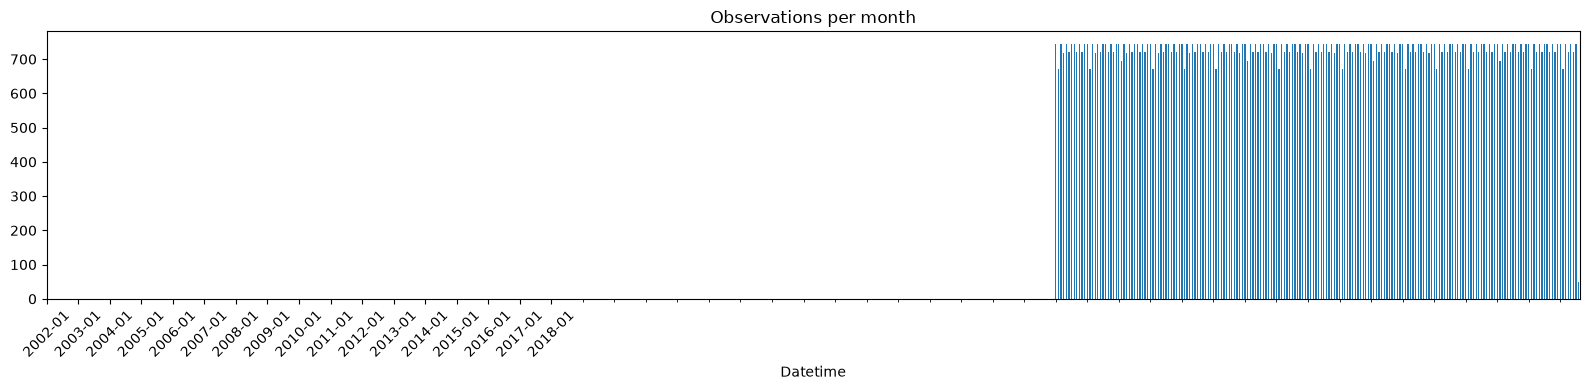

Min obs in a month: 49 | Max: 744


In [21]:
counts = d.dt.to_period("M").value_counts().sort_index()
counts.plot(kind="bar", figsize=(16, 4), title="Observations per month")
plt.xticks(range(0, len(counts), 12), [str(p) for p in counts.index[::12]], rotation=45)
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "01_obs_per_month.png")
plt.show()

print("Min obs in a month:", counts.min(), "| Max:", counts.max())

## First look at the series

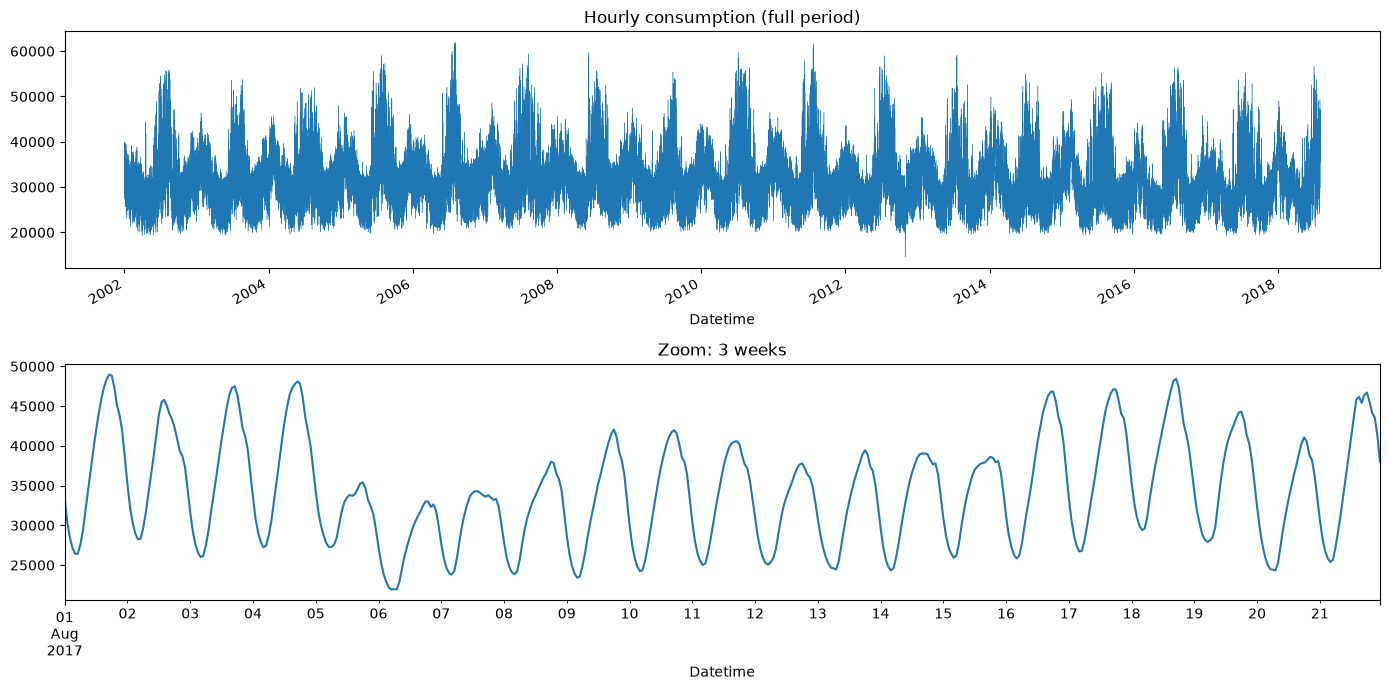

In [28]:
s = df.sort_values(cfg.DATETIME_COL).set_index(cfg.DATETIME_COL)[cfg.TARGET_COL]
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
s.plot(ax=ax[0], lw=0.3, title="Hourly consumption (full period)")
s["2017-08-01":"2017-08-21"].plot(ax=ax[1], title="Zoom: 3 weeks")
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "01_series_overview.png")
plt.show()

In [29]:
# Anomaly candidates (for the cleaning step)
print("Top 10 highest values:")
print(s.nlargest(10))
print("\nTop 10 lowest values:")
print(s.nsmallest(10))

Top 10 highest values:
Datetime
2006-08-02 17:00:00    62009.0
2006-08-02 16:00:00    61909.0
2006-08-03 17:00:00    61796.0
2006-08-03 16:00:00    61770.0
2011-07-22 15:00:00    61646.0
2006-08-01 17:00:00    61643.0
2006-08-02 15:00:00    61641.0
2006-08-02 18:00:00    61610.0
2011-07-22 16:00:00    61608.0
2011-07-22 14:00:00    61532.0
Name: PJME_MW, dtype: float64

Top 10 lowest values:
Datetime
2012-10-30 04:00:00    14544.0
2012-10-30 03:00:00    14586.0
2012-10-30 05:00:00    14821.0
2012-10-30 02:00:00    14955.0
2012-10-30 01:00:00    15390.0
2012-10-30 06:00:00    15526.0
2012-10-30 00:00:00    15919.0
2012-10-30 07:00:00    16688.0
2012-10-29 23:00:00    17422.0
2012-10-30 08:00:00    17734.0
Name: PJME_MW, dtype: float64
